In [ ]:
#Load the dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [ ]:
diabetes_data = load_diabetes(as_frame=True)

df = diabetes_data.frame

df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [ ]:
#Select features and target
X = df.drop("target", axis=1)
y = df["target"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  

Target:
0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: target, dtype: float64


In [ ]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
#Define the models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000)
}

In [ ]:
#Create the model pipeline
def create_pipeline(regressor):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", regressor)
    ])


In [ ]:
#Train and evaluate the models
def evaluate_model(name, regressor):
    model = create_pipeline(regressor)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mse = mean_squared_error(y_test, predictions)

    return {
        "Model": name,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_test, predictions),
        "Predictions": predictions
    }

In [ ]:
#Compare model performance
results = [
    evaluate_model(name, regressor)
    for name, regressor in models.items()
]

results_table = pd.DataFrame([
    {
        "Model": result["Model"],
        "MSE": result["MSE"],
        "RMSE": result["RMSE"],
        "R2 Score": result["R2 Score"]
    }
    for result in results
])

results_table.round(4)

,Model,MSE,RMSE,R2 Score
0,Linear Regression,2900.1936,53.8534,0.4526
1,Ridge Regression,2892.0146,53.7775,0.4541
2,Lasso Regression,2884.6243,53.7087,0.4555


In [ ]:
#Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual Values": y_test.reset_index(drop=True)
})

for result in results:
    comparison[result["Model"]] = result["Predictions"]

comparison.head(10).round(2)

,Actual Values,Linear Regression,Ridge Regression,Lasso Regression
0,219.0,139.55,139.86,140.23
1,70.0,179.52,179.96,180.32
2,202.0,134.04,135.72,137.01
3,230.0,291.42,292.12,291.37
4,111.0,123.79,123.19,122.81
5,84.0,92.17,92.63,92.63
6,242.0,258.23,257.86,257.89
7,272.0,181.34,182.98,184.45
8,94.0,90.22,88.57,88.03
9,96.0,108.63,109.34,109.99


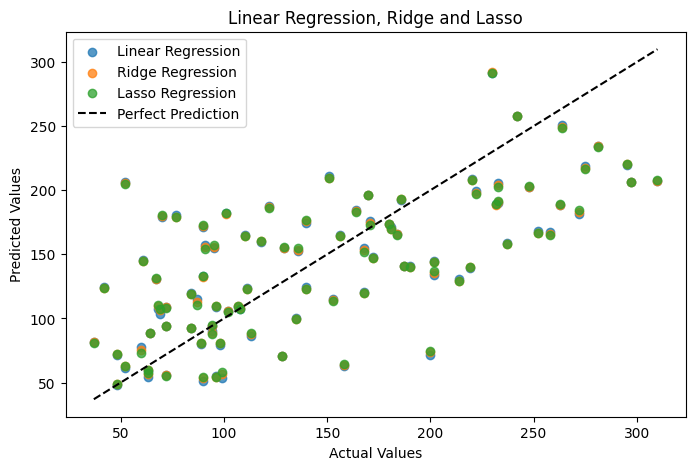

In [ ]:
#Plot actual vs predicted values
plt.figure(figsize=(8, 5))

for result in results:
    plt.scatter(
        y_test,
        result["Predictions"],
        label=result["Model"],
        alpha=0.75
    )

limits = [y_test.min(), y_test.max()]

plt.plot(limits, limits, "k--", label="Perfect Prediction")

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression, Ridge and Lasso")
plt.legend()
plt.show()
